# Only trade the big moves — Stage 2: mean reversion in FX and commodities

**Project:** Mean reversion across FX and commodities · **Stage 2 of 4** · Heritage Edge

### Where Stage 1 left us
Betting that *every* daily move undoes itself didn't work in EURUSD, USDJPY, gold or oil:
* the pattern was faint (only gold's dip days passed the luck test),
* the strategy traded ~130 times a year, so costs ate most of the profit,
* and trading one day late wiped out everything.

### The Stage 2 idea, explained simply
Most daily moves are just **noise** — like a bus rocking a little at every bump. Betting on every wobble means paying the spread over and over for nothing.

So Stage 2 asks: **what if we only act when the move was unusually big?** A rubber band pulled a tiny bit barely snaps back; pulled hard, it snaps back more. If mean reversion exists anywhere, the big moves are the place to look.

Three upgrades:
1. **Measure every move against that market's normal wobble** (a *z-score*), so "big" means the same thing in EURUSD and in oil.
2. **Only trade when yesterday's move was big** — far fewer trades, far less cost.
3. **Size each trade by risk**, so a quiet market and a wild market carry the same risk.

And one fairness fix: gold and USDJPY drifted upwards for years, so we compare against a **normal day** in that market, not against zero.

> As in Stage 1, "no edge" is an acceptable answer. What matters is that the test is fair.

## 1. Setup
In VS Code, run this once. (In Colab, `%pip` works too.)

In [1]:
%pip install -q yfinance pandas numpy matplotlib jinja2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)

## 2. Settings

Same markets and costs as Stage 1, so the two stages compare like for like. Three new settings:

| Setting | What it means |
|---|---|
| `VOL_WINDOW` | How many past days we use to judge a market's "normal wobble" (20 days ≈ one month) |
| `TARGET_VOL` | How bumpy we want each trade to be, per year (10%). Used for sizing |
| `MAX_LEVERAGE` | A safety cap: never trade more than 3× the account, even in a very quiet market |

In [3]:
MARKETS = {
    "EURUSD"  : "EURUSD=X",
    "USDJPY"  : "JPY=X",
    "Gold"    : "GC=F",
    "WTI oil" : "CL=F",
}
COST_BPS = {"EURUSD": 0.5, "USDJPY": 0.7, "Gold": 1.5, "WTI oil": 2.5}   # one-way, per unit traded

START, END   = "2012-01-01", "2026-10-01"
TRADING_DAYS = 252

VOL_WINDOW   = 20      # days used to measure normal wobble
TARGET_VOL   = 0.10    # 10% a year per trade
MAX_LEVERAGE = 3.0     # never more than 3x the account

## 3. Download and clean the prices
Exactly the same steps as Stage 1: drop missing days, remove prices at or below zero (oil in April 2020), and flag any day that moved more than 10%.

In [4]:
def download_closes(markets, start, end):
    closes = {}
    for name, ticker in markets.items():
        data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=False)
        if data.empty:
            raise ValueError(f"No data came back for {name} ({ticker}). Check the ticker or your internet.")
        close = data["Close"]
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
        closes[name] = close.rename(name)
    return closes

def clean(close, name):
    s = close.dropna()
    s = s[~s.index.duplicated(keep="last")].sort_index()
    bad = s[s <= 0]
    if len(bad):
        print(f"{name}: removed {len(bad)} day(s) with price <= 0 -> {list(bad.index.date)}")
    s = s[s > 0]
    big = np.log(s).diff().abs()
    big = big[big > 0.10]
    if len(big):
        print(f"{name}: {len(big)} day(s) moved more than 10% -> {list(big.index.date)}")
    return s

raw = download_closes(MARKETS, START, END)
prices = {name: clean(s, name) for name, s in raw.items()}

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

Gold: 1 day(s) moved more than 10% -> [datetime.date(2026, 1, 30)]
WTI oil: removed 1 day(s) with price <= 0 -> [datetime.date(2020, 4, 20)]
WTI oil: 28 day(s) moved more than 10% -> [datetime.date(2014, 11, 28), datetime.date(2016, 1, 21), datetime.date(2016, 2, 12), datetime.date(2019, 9, 16), datetime.date(2020, 3, 6), datetime.date(2020, 3, 9), datetime.date(2020, 3, 16), datetime.date(2020, 3, 18), datetime.date(2020, 3, 19), datetime.date(2020, 3, 20), datetime.date(2020, 4, 2), datetime.date(2020, 4, 3), datetime.date(2020, 4, 14), datetime.date(2020, 4, 21), datetime.date(2020, 4, 22), datetime.date(2020, 4, 23), datetime.date(2020, 4, 27), datetime.date(2020, 4, 29), datetime.date(2020, 4, 30), datetime.date(2020, 5, 5), datetime.date(2021, 11, 26), datetime.date(2022, 3, 9), datetime.date(2026, 3, 6), datetime.date(2026, 3, 10), datetime.date(2026, 3, 23), datetime.date(2026, 4, 2), datetime.date(2026, 4, 8), datetime.date(2026, 4, 17)]


/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

## 4. How big was yesterday's move — *for this market*?

### Why we need a ruler
A 1% move in EURUSD is a big day. A 1% move in oil is a quiet day. To compare them, we measure each move in units of that market's **normal wobble** (its recent *volatility*):

$$z_t = \frac{r_t}{\sigma_{t-1}}$$

* $r_t$ = today's log return (how much the price moved).
* $\sigma_{t-1}$ = the standard deviation of the previous 20 days' returns — "how much does this market usually wiggle?". It uses **only past days**, so we never peek at today.

> **Everyday example:** your friend is 10 minutes late. If they're usually on time, that's unusual (big $z$). If they're always 15 minutes late, it's nothing (small $z$).

Rough guide: $|z| < 1$ is an ordinary day. $|z| > 2$ happens on roughly 1 day in 20 — a genuinely big move.

### Sizing by risk
We also use $\sigma$ to decide **how much to trade**, so every trade carries the same risk:

$$\text{size}_t = \min\!\left(\frac{\text{target daily vol}}{\sigma_{t-1}},\ \text{max leverage}\right), \qquad \text{target daily vol} = \frac{10\%}{\sqrt{252}}$$

> **Everyday example:** you'd carry one bag of bricks but five bags of feathers. A calm market (EURUSD) gets a bigger position; a wild one (oil) gets a smaller one.

In [5]:
def make_frame(close):
    df = pd.DataFrame({"close": close})
    df["log_ret"]    = np.log(df["close"]).diff()
    df["simple_ret"] = df["close"].pct_change()
    df["vol"]        = df["log_ret"].rolling(VOL_WINDOW).std().shift(1)    # normal wobble, past days only
    df["z"]          = df["log_ret"] / df["vol"]                            # today's move, in wobble units
    df["prev_z"]     = df["z"].shift(1)                                     # yesterday's move, in wobble units
    df["prev_vol"]   = df["vol"].shift(1)                                   # wobble known when we decide
    daily_target     = TARGET_VOL / np.sqrt(TRADING_DAYS)
    df["size"]       = (daily_target / df["prev_vol"]).clip(upper=MAX_LEVERAGE)
    return df.dropna()

frames = {name: make_frame(s) for name, s in prices.items()}
frames["EURUSD"][["close", "log_ret", "vol", "z", "prev_z", "size"]].tail()

,close,log_ret,vol,z,prev_z,size
Date,,,,,,
2026-09-24,1.1382,-0.0058,0.0024,-2.4491,-0.6102,2.6420
2026-09-25,1.1375,-0.0006,0.0026,-0.2412,-2.4491,2.6658
2026-09-28,1.1378,0.0003,0.0026,0.1103,-0.2412,2.4285
2026-09-29,1.1373,-0.0005,0.0024,-0.1976,0.1103,2.4423
2026-09-30,1.1341,-0.0028,0.0022,-1.2601,-0.1976,2.6686


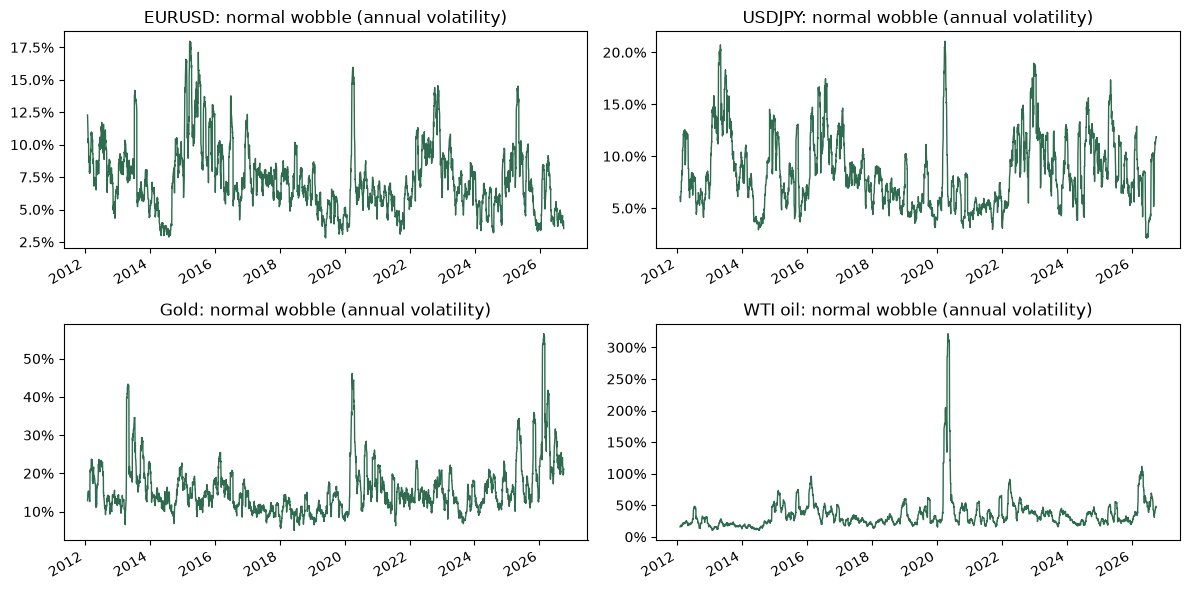

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (name, df) in zip(axes.flat, frames.items()):
    (df["vol"] * np.sqrt(TRADING_DAYS)).plot(ax=ax, color="#2E6B4F", lw=1)
    ax.set_title(f"{name}: normal wobble (annual volatility)")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 5. Step 1 — Do bigger moves snap back harder?

We sort every day by **how big yesterday's move was** (its $z$), into buckets from "big fall" to "big rise". Then we look at the **average move today**, also measured in wobble units.

If the rubber band gets stronger the harder you pull it, the chart should **slope downwards**:
* after a **big fall** (left), today's average move is **up** (positive bar),
* after a **big rise** (right), today's average move is **down** (negative bar),
* and the bars at the edges are **taller** than the ones in the middle.

### The fairness fix
Gold and USDJPY rose for years, so *any* day in them tended to be slightly positive. We subtract each market's **average day** before comparing, so a bar only shows the *extra* move caused by yesterday.

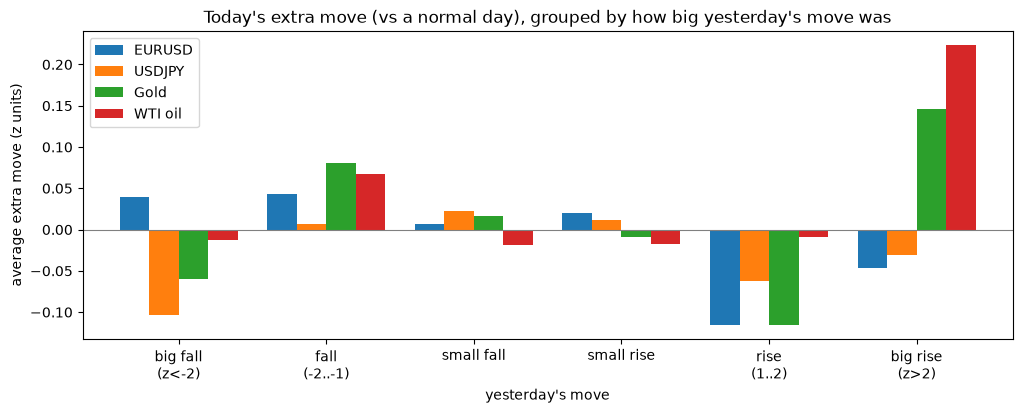

days  avg extra move (z units)  t-stat
market  yesterday                                              
EURUSD  big fall (z<-2)   120                    0.0397  0.4367
        fall (-2..-1)     444                    0.0426  0.8591
        small fall       1390                    0.0071  0.2442
        small rise       1283                    0.0199  0.6553
        rise (1..2)       464                   -0.1158 -2.2579
        big rise (z>2)    115                   -0.0463 -0.3685
USDJPY  big fall (z<-2)   130                   -0.1034 -0.9151
        fall (-2..-1)     415                    0.0065  0.1038
        small fall       1235                    0.0229  0.7460
        small rise       1432                    0.0116  0.4010
        rise (1..2)       484                   -0.0629 -1.2998
        big rise (z>2)    121                   -0.0307 -0.2979
Gold    big fall (z<-2)   142                   -0.0601 -0.6459
        fall (-2..-1)     333                    0.0807  1.5067
        small fall       1306                    0.0163  0.5190
        small rise       1363                   -0.0089 -0.2876
        rise (1..2)       407                   -0.1157 -2.0495
        big rise (z>2)    134                    0.1465  1.5769
WTI oil big fall (z<-2)   145                   -0.0125 -0.0984
        fall (-2..-1)     430                    0.0671  1.2685
        small fall       1182                   -0.0189 -0.5481
        small rise       1365                   -0.0173 -0.6218
        rise (1..2)       459                   -0.0090 -0.1812
        big rise (z>2)    103                    0.2234  2.0103

In [7]:
BINS   = [-np.inf, -2, -1, 0, 1, 2, np.inf]
LABELS = ["big fall\n(z<-2)", "fall\n(-2..-1)", "small fall", "small rise", "rise\n(1..2)", "big rise\n(z>2)"]

def t_stat(x):
    x = pd.Series(x).dropna()
    return x.mean() / (x.std() / np.sqrt(len(x))) if len(x) > 1 else np.nan

bucket_rows, bucket_means = [], {}
for name, df in frames.items():
    excess = df["z"] - df["z"].mean()                     # today's move vs a normal day
    groups = excess.groupby(pd.cut(df["prev_z"], BINS, labels=LABELS), observed=False)
    bucket_means[name] = groups.mean()
    for label, g in groups:
        bucket_rows.append({"market": name, "yesterday": label.replace("\n", " "),
                            "days": len(g), "avg extra move (z units)": g.mean(), "t-stat": t_stat(g)})

buckets = pd.DataFrame(bucket_rows).set_index(["market", "yesterday"])
pd.DataFrame(bucket_means).plot(kind="bar", figsize=(12, 4), width=0.8, rot=0)
plt.axhline(0, color="grey", lw=0.8)
plt.title("Today's extra move (vs a normal day), grouped by how big yesterday's move was")
plt.ylabel("average extra move (z units)"); plt.xlabel("yesterday's move"); plt.show()
buckets

**How to read the table:** focus on the two edge rows — "big fall" and "big rise". A real snap-back needs a **positive** average after a big fall and a **negative** one after a big rise, with t-stats beyond about ±2. Be aware the edge buckets hold far fewer days (often 100–200), so their t-stats are naturally smaller.

## 6. Was gold's "buy the dip" real, or just the bull market?

Stage 1 found gold rose 6.8 bps on average after down days. But gold rose on average on **all** days. The fair question is:

> *Do days after a fall beat an ordinary day?*

We compare two groups of days in each market — **days after a fall** vs **all other days** — and test whether the gap between them is bigger than luck. (This is a *Welch t-test*: the same "signal vs noise" idea as before, but for the gap between two groups.)

In [8]:
def welch_t(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    return (a.mean() - b.mean()) / np.sqrt(a.var() / len(a) + b.var() / len(b))

dip_rows = []
for name, df in frames.items():
    for label, mask in [("after any fall", df["prev_z"] < 0), ("after a big fall (z<-2)", df["prev_z"] < -2)]:
        after, other = df.loc[mask, "log_ret"], df.loc[~mask, "log_ret"]
        dip_rows.append({"market": name, "days": label, "count": len(after),
                         "avg move after (bps)": after.mean() * 1e4,
                         "avg move on other days (bps)": other.mean() * 1e4,
                         "gap (bps)": (after.mean() - other.mean()) * 1e4,
                         "t-stat of gap": welch_t(after, other)})
pd.DataFrame(dip_rows).set_index(["market", "days"])

count  avg move after (bps)  \
market  days                                                   
EURUSD  after any fall            1935                0.6696   
        after a big fall (z<-2)    120                2.4456   
USDJPY  after any fall            1776                2.7908   
        after a big fall (z<-2)    130               -1.4508   
Gold    after any fall            1764                6.5056   
        after a big fall (z<-2)    142               -6.6873   
WTI oil after any fall            1745                4.0101   
        after a big fall (z<-2)    145               41.5338   

                                 avg move on other days (bps)  gap (bps)  \
market  days                                                               
EURUSD  after any fall                                -1.4715     2.1410   
        after a big fall (z<-2)                       -0.4777     2.9233   
USDJPY  after any fall                                 1.1157     1.6751   
        after a big fall (z<-2)                        2.0131    -3.4639   
Gold    after any fall                                -1.4533     7.9589   
        after a big fall (z<-2)                        2.7191    -9.4065   
WTI oil after any fall                                -3.9370     7.9471   
        after a big fall (z<-2)                       -1.8815    43.4153   

                                 t-stat of gap  
market  days                                    
EURUSD  after any fall                  1.3540  
        after a big fall (z<-2)         0.6337  
USDJPY  after any fall                  0.8939  
        after a big fall (z<-2)        -0.5675  
Gold    after any fall                  2.2471  
        after a big fall (z<-2)        -0.8963  
WTI oil after any fall                  0.8264  
        after a big fall (z<-2)         1.0764

## 7. Step 2 — The big-move strategy

### The rule
$$\text{position}_t =
\begin{cases}
-\,\text{sign}(z_{t-1}) \times \text{size}_t & \text{if } |z_{t-1}| > k \\
0 & \text{otherwise}
\end{cases}$$

In words: **if yesterday's move was bigger than $k$ wobbles, bet against it for one day, sized by risk. Otherwise, do nothing.** $k$ is the *threshold*.

Costs, compounding and turnover work exactly like Stage 1 — we pay the spread only when the position changes, and now the position can be any size, not just ±1.

### How do we choose $k$ without cheating?
If we tried lots of thresholds on all the data and kept the best one, the result would look great *because we picked it after seeing the answer* — like choosing your lottery numbers after the draw. This is called **overfitting**.

So we do it properly:
1. **Training period** (first 75% of the data, ~2012–2022): try several thresholds, pick the best one for each market.
2. **Test period** (last 25%, ~2023 onwards): run that threshold on data it has **never seen**. Only this result counts.

In [14]:
def run_strategy(df, cost_bps, k=1.5, delay=0, sized=True):
    out = df.copy()
    prev_z = out["prev_z"].shift(delay)
    size   = out["size"].shift(delay) if sized else 1.0
    signal = pd.Series(np.where(prev_z.abs() > k, -np.sign(prev_z), 0.0), index=out.index)
    out["position"]  = (signal * size).fillna(0)
    out["turnover"]  = out["position"].diff().abs().fillna(out["position"].abs())
    out["cost"]      = out["turnover"] * cost_bps / 1e4
    out["gross_ret"] = out["position"] * out["simple_ret"]
    out["net_ret"]   = out["gross_ret"] - out["cost"]
    out["net_equity"] = (1 + out["net_ret"]).cumprod()
    return out

def scorecard(ret, position=None, turnover=None, cost=None):
    ret = ret.dropna()
    years = len(ret) / TRADING_DAYS
    equity = (1 + ret).cumprod()
    sd = ret.std()
    card = {
        "CAGR":         equity.iloc[-1] ** (1 / years) - 1,
        "Volatility":   sd * np.sqrt(TRADING_DAYS),
        "Sharpe":       ret.mean() / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan,
        "Max drawdown": (equity / equity.cummax() - 1).min(),
        "Win rate":     (ret[position != 0] > 0).mean() if position is not None else (ret[ret != 0] > 0).mean(),
        "t-stat":       t_stat(ret),
    }
    if position is not None:
        direction = np.sign(position)
        card["Days in market"] = (direction != 0).mean()
        # a "trade" = opening, closing or flipping a position (not small daily resizing)
        card["Trades / year"] = (direction.diff().fillna(direction) != 0).sum() / years
    if cost is not None:
        card["Cost drag / year"] = cost.sum() / years
    return card

FMT = {"CAGR": "{:.1%}", "Volatility": "{:.1%}", "Max drawdown": "{:.1%}", "Win rate": "{:.1%}",
       "Days in market": "{:.0%}", "Cost drag / year": "{:.2%}",
       "Sharpe": "{:.2f}", "t-stat": "{:.2f}", "Trades / year": "{:.0f}"}

### Trying thresholds on the training period
For each market we try $k$ from 0 (trade every day, like Stage 1) up to 3 (only the rarest moves), and record the **training-period** Sharpe after costs.

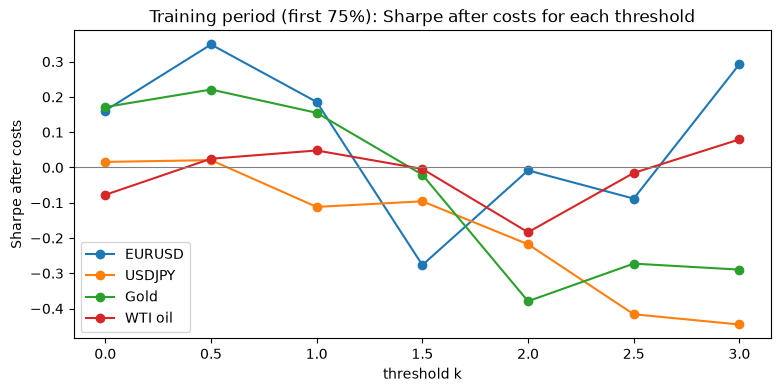

Threshold chosen on the training period:
EURUSD    0.5000
USDJPY    0.5000
Gold      0.5000
WTI oil   3.0000


,EURUSD,USDJPY,Gold,WTI oil
threshold k,,,,
0.0000,0.1600,0.0200,0.1700,-0.0800
0.5000,0.3500,0.0200,0.2200,0.0200
1.0000,0.1900,-0.1100,0.1500,0.0500
1.5000,-0.2800,-0.1000,-0.0200,-0.0000
2.0000,-0.0100,-0.2200,-0.3800,-0.1800
2.5000,-0.0900,-0.4200,-0.2700,-0.0200
3.0000,0.2900,-0.4500,-0.2900,0.0800


In [15]:
THRESHOLDS = [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]

splits = {name: int(len(df) * 0.75) for name, df in frames.items()}
train_sharpe = pd.DataFrame({
    name: [scorecard(run_strategy(df, COST_BPS[name], k=k)["net_ret"].iloc[:splits[name]])["Sharpe"]
           for k in THRESHOLDS]
    for name, df in frames.items()
}, index=THRESHOLDS)
train_sharpe.index.name = "threshold k"

ax = train_sharpe.plot(marker="o", figsize=(9, 4))
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Training period (first 75%): Sharpe after costs for each threshold")
ax.set_ylabel("Sharpe after costs"); plt.show()

chosen_k = train_sharpe.idxmax()
print("Threshold chosen on the training period:"); print(chosen_k.to_string())
train_sharpe.round(2)

### The real test: the period the strategy has never seen
Now we run each market with its chosen threshold on the **test period only**, and put Stage 1's strategy next to it for comparison over the same days.

In [16]:
test_cards = {}
for name, df in frames.items():
    cut, k = splits[name], chosen_k[name]
    s2 = run_strategy(df, COST_BPS[name], k=k).iloc[cut:]
    s1 = run_strategy(df, COST_BPS[name], k=0, sized=False).iloc[cut:]     # Stage 1 rule, same days
    test_cards[(name, "Stage 1 (every day)")] = scorecard(s1["net_ret"], s1["position"], s1["turnover"], s1["cost"])
    test_cards[(name, f"Stage 2 (k={k})")]    = scorecard(s2["net_ret"], s2["position"], s2["turnover"], s2["cost"])

pd.DataFrame(test_cards).T.style.format(FMT, na_rep="—")

## 8. Equity curves over the whole period

For the picture, here is each market's Stage 2 strategy (with its chosen threshold) over all years, after costs. The **dashed vertical line** marks where the training period ends and the unseen test period begins — only the part to the right of it is a fair test.

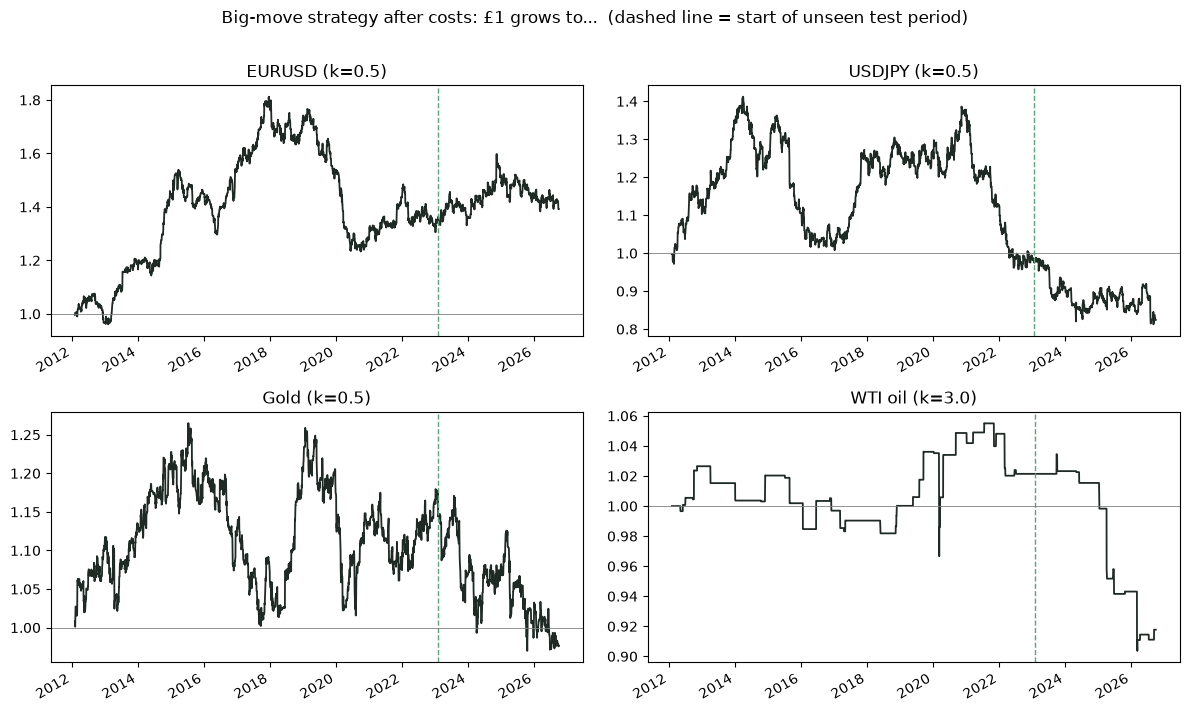

In [17]:
full = {name: run_strategy(df, COST_BPS[name], k=chosen_k[name]) for name, df in frames.items()}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (name, r) in zip(axes.flat, full.items()):
    r["net_equity"].plot(ax=ax, color="#1F2A24", lw=1.3)
    ax.axvline(r.index[splits[name]], color="#5DA37A", ls="--", lw=1)
    ax.axhline(1, color="grey", lw=0.6)
    ax.set_title(f"{name} (k={chosen_k[name]})"); ax.set_xlabel("")
plt.suptitle("Big-move strategy after costs: £1 grows to...  (dashed line = start of unseen test period)", y=1.01)
plt.tight_layout(); plt.show()

## 9. The two stress tests from Stage 1

**Costs:** does the test-period Sharpe survive if trading costs 2× or 3× what we assumed?

**One day late:** does it survive if we act a day after the big move instead of at the close?

> Fewer trades should make Stage 2 **much less sensitive to costs** than Stage 1. If it still collapses when we're a day late, the snap-back happens almost immediately — which tells us a daily strategy is the wrong tool, and faster (intraday) data would be needed.

In [18]:
stress = {}
for name, df in frames.items():
    cut, k = splits[name], chosen_k[name]
    row = {}
    for m in [0, 1, 2, 3]:
        row[f"Sharpe @ {m}x costs"] = scorecard(run_strategy(df, COST_BPS[name] * m, k=k)["net_ret"].iloc[cut:])["Sharpe"]
    row["Sharpe, one day late"] = scorecard(run_strategy(df, COST_BPS[name], k=k, delay=1)["net_ret"].iloc[cut:])["Sharpe"]
    stress[name] = row
pd.DataFrame(stress).T.round(2)

,Sharpe @ 0x costs,Sharpe @ 1x costs,Sharpe @ 2x costs,Sharpe @ 3x costs,"Sharpe, one day late"
EURUSD,0.3500,0.1500,-0.0500,-0.2500,-0.1200
USDJPY,-0.2300,-0.4100,-0.5900,-0.7700,0.1400
Gold,-0.3100,-0.5500,-0.7800,-1.0100,-0.8800
WTI oil,-0.8600,-0.8800,-0.9000,-0.9300,-0.2000


## 10. Findings

* **Do bigger moves snap back harder?** No. The biggest moves (more than 2 normal days' worth) showed no reliable snap-back in any market. In gold and oil they tended to continue instead: after a big rise, oil rose a further 0.22 normal-day units on average (t = 2.0). The only reversal appeared in medium-sized moves (1–2 normal days), e.g. EURUSD (t = −2.3) and gold (t = −2.0) after moderate rises. A likely explanation: medium moves are mostly noise that fades, while the biggest moves are driven by news the market keeps pricing in. With 24 buckets tested, about 1 pass by luck is expected and we got 3, so this is a hint rather than proof.

* **Was gold's dip-buying real?** Partly. Compared with ordinary gold days, days after a fall were 8.0 bps better on average (t = 2.25), so the Stage 1 effect isn't just gold's bull market. But it only applies to normal-sized dips: after big falls gold tended to keep falling (−9.4 bps vs other days, t = −0.9). No other market showed a gap that clears the luck test.

* **Which threshold did training pick, and why?** k = 0.5 for EURUSD, USDJPY and gold, and 3.0 for oil. Higher thresholds generally made results worse, consistent with big moves continuing. Even choosing with hindsight, the best training Sharpe was only 0.35, and results jumped around between thresholds — a sign of noise. Oil's 3.0 rests on a 0.08 Sharpe from about 8 trades a year.

* **Does it work on unseen data?** No. On 2023 onwards, Sharpe was 0.15 (EURUSD), −0.41 (USDJPY), −0.55 (gold) and −0.88 (oil), with no t-stat beyond ±1.7, and worse than Stage 1 for gold and oil. The low threshold didn't cut trading either: Stage 2 traded about 160 times a year vs 125, because it kept stepping in and out of the market.

* **Does it survive the stress tests?** No. In the unseen period, USDJPY, gold and oil lose money even with free trading, so the signal itself is the problem. EURUSD is positive before costs (0.35) but turns negative at about 1.7× our cost estimate. Trading one day late leaves all but USDJPY (0.14, noise) negative.

**Verdict:** Filtering for big moves doesn't rescue single-market mean reversion in FX and commodities. The biggest moves tend to continue rather than reverse, and the one real-looking effect — gold bouncing after ordinary dips — is too small to trade on its own.

## What comes next
* **Stage 3 — trade the gap between cousins.** If single markets don't snap back, pairs that are tied together by economics might: gold vs silver, Brent vs WTI, AUDUSD vs NZDUSD. When the gap stretches unusually wide, bet it closes.
* **Stage 4 — the honesty layer.** Futures roll handling, overnight swap costs, and rolling (walk-forward) re-training instead of one train/test split.